**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 1, notebook 2 of 2

| | |
|---|---|
| **Goal** | Answer the Step 2 questions of the PW (competitive landscape): measure how concentrated your sector is, who the incumbents and the entrants are, which subfields grow, and which forces shape it. |
| **Before this** | 10 · Patent attributes; Step 1 of the PW |
| **Time** | 90 min |
| **PATSTAT environment** | TEST (switch to PROD for final numbers) |

← [10 · Patent attributes](10_patent_attributes.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)

<sub>Adapted from the EPO TIP training materials (https://github.com/epo/tip-training). This version has been modified and is not authorised by the EPO; the EPO is not responsible for its correctness. Section 4 replicates Liston-Heyes, C. & Pilkington, A. (2004), *Inventive concentration in the production of green technology: a comparative analysis of fuel cell patents*, Science and Public Policy, 31(1), 15–25, available in the academic_papers folder.</sub>

# Step 2 of the PW: Competitive landscape

| Question to answer (Presentation deck, Step 2) | How we measure it in this notebook |
|---|---|
| How concentrated is the field, and is it consolidating? | Six measures of concentration from the literature (Sections 3–4); the Herfindahl index and the 4-firm ratio over time (Section 5.1) |
| Who are the incumbents, and who are the new entrants? | Top applicants with type and country; new applicants per year, their share of families, and the rate of disappearance (Section 5.2) |
| Which subfields are growing fastest? | Growth of the CPC groups of the sector between two periods (Section 5.3) |
| Which political, economic, social and technological forces shape it? | PEST analysis of the political, economic, social and technological forces, with sources outside PATSTAT (Section 5.4) |

Section 2.4 has a **Your turn** exercise on the harmonisation of applicant names.

**Contents**

1. Setup and configuration
2. The unit of analysis: applicants, and how to consolidate their names (with an exercise on a gold standard)
3. Proxies for concentration: six measures from the literature
4. Example: inventive concentration in fuel cells (Liston-Heyes & Pilkington, 2004)
5. Answering the Step 2 questions for your sector

## 1. Setup and configuration

In [1]:
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # linear regression (Lotka) and Kendall's tau
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons: standardised name, sector, country
    TLS207_PERS_APPLN,          # person <-> application links (applicant / inventor)
    TLS209_APPLN_IPC,           # IPC classification
    TLS211_PAT_PUBLN,           # publications: grants and their dates
    TLS224_APPLN_CPC,           # CPC classification
)

In [2]:
# ---------------------------------------------------------------- environment
ENV = "TEST"                         # develop on TEST, switch to "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- applicant names (Section 2)
NAME_METHOD = "dictionary"           # "psn" (PATSTAT names as they are), "dictionary" or "cleanco"
GOLD_STANDARD_FILE = "PATSTAT_500_label_datav4.csv"   # hand-labelled names (Section 2.4), in the same folder as this notebook

# ---------------------------------------------------------------- replication (Section 4): the paper's design
REPL_OFFICE = "US"                                      # USPTO patents...
REPL_GRANTED = (date(1976, 1, 1), date(2002, 12, 31))   # ...granted between these two dates
REPL_KEYWORDS = ("fuel cell",)                          # searched in titles and abstracts
REPL_CLASSES = ("H01M8",)                               # IPC/CPC H01M 8: fuel cells
REPL_SELECTION = "keywords or classes"                  # "keywords", "classes" or "keywords or classes"
PAPER_COUNTRIES = ("AU", "CA", "FR", "DE", "IL", "IT", "JP", "NL", "SE", "CH", "GB", "US")

# ---------------------------------------------------------------- your sector (Section 5): replace with your Step 1
SECTOR_NAME = "Fuel cells"
SECTOR_CPC_PREFIXES = (
    "H01M8",                 # fuel cells; manufacture thereof
    "Y02E60/50",             # fuel cells (climate change mitigation tagging)
)
SECTOR_KEYWORDS = ()         # optional, e.g. ("fuel cell",)
YEAR_MIN, YEAR_MAX = 2000, 2025
LAST_COMPLETE_YEAR = YEAR_MAX - 3    # the last 3 priority years are still incomplete in PATSTAT
IPR_TYPE = "PI"                      # patents of invention only
SPLIT_YEAR = 2015                    # incumbents file before SPLIT_YEAR, entrants from SPLIT_YEAR on
WINDOW = 3                           # years per window when following concentration over time
TOP_N = 15                           # rows in the tables of top applicants

COUNTRY_NAMES = {"AU": "Australia", "CA": "Canada", "FR": "France", "DE": "Germany", "IL": "Israel", "IT": "Italy",
                 "JP": "Japan", "NL": "Netherlands", "SE": "Sweden", "CH": "Switzerland", "GB": "UK", "US": "USA"}

In [3]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

## 2. The unit of analysis: applicants

In Step 1 we counted **families** and **applications**. Concentration needs one more unit: the **applicant**, the owner of the patent. We must decide when two names on two patents are **the same applicant**.

### 2.1 The "name game"

The same company appears in PATSTAT under many spellings (*SIEMENS AG*, *Siemens Aktiengesellschaft*, *SIEMENS AKTIENGESELLSCHAFT MUENCHEN*…). If we count each spelling as a different firm, a large firm is split into many small ones and **every concentration measure is wrong**. `tls206_person` offers:

| Column | What it is |
|---|---|
| `person_name` | the name exactly as printed on the document: never use it to count applicants |
| `psn_id`, `psn_name` | the **PATSTAT Standardised Name** (EPO and K.U. Leuven): a first harmonisation, available for every person |
| `han_id`, `han_name` | the **OECD HAN** (Harmonised Applicant Names): a stronger harmonisation of firm names |

`psn_name` is a good start, but it still leaves variants (*TOYOTA JIDOSHA KK* and *TOYOTA MOTOR CORP*, with and without legal forms…), and it never merges a subsidiary with its parent.

### 2.2 Three possible ways to consolidate names further

| Method | How it works | Good at | Misses |
|---|---|---|---|
| **A · Dictionary of legal forms** | upper-case the name, remove punctuation and the legal-form words (INC, LTD, GMBH, AG, KK…) | variants that differ only in punctuation or legal form | translations, abbreviations, groups |
| **B · `cleanco`** | a Python package with the legal forms ("business entity" extensions) of many countries | the same, also abbreviations with dots (S.p.A., N.V.) | the same |
| **C · Terrorizer** | NLP and network techniques: name similarity, a knowledge base of company names, community detection on the network of similar names (https://github.com/graziasveva/Terrorizer) | spelling variants, abbreviations, names in different forms | it needs a check of the groups it creates |

Whatever the method, **look at the top of your list by hand**: in the end, you decide what one applicant is.

**Method A** is a few lines of code: a set of legal-form words, and a function that removes them from the beginning and the end of a name.

In [6]:
# Legal-form words to remove (extend the set for the countries of your sector)
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
}


def clean_with_dictionary(name):
    "Upper-case, keep letters and digits only, and drop legal-form words at the start and at the end."
    words = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split()
    while words and words[-1] in LEGAL_FORMS:      # e.g. "TOYOTA JIDOSHA KABUSHIKI KAISHA" -> "TOYOTA JIDOSHA"
        words.pop()
    while words and words[0] in LEGAL_FORMS:       # e.g. "KABUSHIKI KAISHA TOSHIBA" -> "TOSHIBA"
        words.pop(0)
    return " ".join(words)


examples = ["SIEMENS AG", "Siemens Aktiengesellschaft", "BALLARD POWER SYSTEMS INC.", "Ballard Power Systems",
            "TOYOTA JIDOSHA KABUSHIKI KAISHA", "KABUSHIKI KAISHA TOSHIBA", "Toyota Motor Corp",
            "FIAT S.p.A.", "Umicore N.V."]
pd.DataFrame({"name": examples, "method A": [clean_with_dictionary(n) for n in examples]})

,name,method A
0,SIEMENS AG,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A
8,Umicore N.V.,UMICORE N V


**Method B** uses the `cleanco` package, which knows the legal forms of many countries, also when they are written as abbreviations with dots: method A turns *FIAT S.p.A.* into *FIAT S P A*, cleanco into *FIAT*. We use cleanco first, then the cleaning of method A.

In [7]:
%pip install -q cleanco
from cleanco import basename


def clean_with_cleanco(name):
    "Remove legal forms with cleanco, then apply the same upper-case cleaning as method A."
    return clean_with_dictionary(basename(str(name)))


pd.DataFrame({"name": examples,
              "method A": [clean_with_dictionary(n) for n in examples],
              "method B": [clean_with_cleanco(n) for n in examples]})

Note: you may need to restart the kernel to use updated packages.


,name,method A,method B
0,SIEMENS AG,SIEMENS,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A,FIAT
8,Umicore N.V.,UMICORE N V,UMICORE


### 2.3 From persons to applicants (`TLS206_PERSON`)


- **`applicant`**: the consolidated name, with the method chosen in `NAME_METHOD`;
- **`type`**: firm, university, individual… from `psn_sector` (the column mixes several labels, so we map it to a few types)
- **`ctry`**: the applicant's country. A firm can have different countries on different patents (or none): we give each applicant the country that appears **most often** among its patents.

In [10]:
def applicant_type(psn_sector):
    "Translate the PATSTAT psn_sector into the types used in the deck."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "HOSPITAL" in s:
        return "hospital"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"


def consolidated_names(psn_names):
    "Dictionary {PATSTAT name: consolidated name}, with the method chosen in NAME_METHOD."
    names = sorted(set(psn_names))
    if NAME_METHOD == "dictionary":
        return {n: clean_with_dictionary(n) for n in names}
    if NAME_METHOD == "cleanco":
        return {n: clean_with_cleanco(n) for n in names}
    return {n: n for n in names}                       # "psn": PATSTAT standardised names as they are


def prepare_applicants(raw):
    "From (unit_id, year, person) rows to one row per (unit_id, applicant) with type and country."
    df = raw.copy()

    # 1. the consolidated name of each applicant
    df["applicant"] = df["psn_name"].map(consolidated_names(df["psn_name"]))

    # 2. the type of applicant
    df["type"] = df["psn_sector"].map(applicant_type)

    # 3. one country per applicant: the most frequent known one
    df["ctry"] = df["ctry"].replace("", np.nan)
    known = df.dropna(subset=["ctry"]).drop_duplicates(["unit_id", "applicant", "ctry"])
    main_country = known.groupby("applicant")["ctry"].agg(lambda c: c.value_counts().index[0])
    df["ctry"] = df["applicant"].map(main_country)

    # 4. one row per (patent, applicant)
    return df[["unit_id", "year", "applicant", "type", "ctry"]].drop_duplicates(["unit_id", "applicant"])

### 2.4 Your turn: harmonise the names of a gold standard

How good is a harmonisation method? To know, we need names for which the right answer is already known: a **gold standard**.

**The data.** The file `PATSTAT_500_label_datav4.csv` (in the same folder as this notebook) contains applicant names as they appear in PATSTAT, grouped by hand. It has two columns:

| Column | What it is |
|---|---|
| `comp` | an applicant name, as written in PATSTAT |
| `Group` | the identifier of the **real organisation** behind the name: names with the same `Group` belong to the same organisation |

In [11]:
gold = pd.read_csv(GOLD_STANDARD_FILE).rename(columns={"comp": "name", "Group": "gold_group"})

print(f"{len(gold):,} names in {gold['gold_group'].nunique():,} organisations")
gold.head(15)

3,192 names in 481 organisations


,gold_group,name
0,1,NOKIA CORPORATION
1,1,NOKIA (DEUTSCHLAND)
2,1,NOKIA GRAETZ
3,2,NOKIA SIEMENS NETWORKS SCHWEIZ
4,1,NOKIA
5,1,NOKIA MOBILE PHONES (U.K.) LIMITED
6,2,NOKIA SIEMENS NETWORKS S.P.A.
7,2,NOKIA SIEMENS NETWORKS
8,1,NOKIA COMMUNICATION
9,1,NOKIA HIGH SPEED ACCESS PRODUCTS


**Your task.** Write a method that harmonises these names: it must give every name a **predicted group**, so that names of the same organisation end up together and names of different organisations stay apart. You can start from methods A and B above, or try anything else.

#### How to measure how well you did: precision, recall and F1

We compare your groups with the gold groups by looking at **pairs of names**. For every pair of names:

| | same gold group | different gold groups |
|---|---|---|
| **same predicted group** (you merged them) | true positive (TP) | false positive (FP) |
| **different predicted groups** (you kept them apart) | false negative (FN) | true negative |

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Precision**: of the pairs you merged, the share that really belong together. It is low when you **merge too much** (two different firms become one).
- **Recall**: of the pairs that belong together, the share you merged. It is low when you **merge too little** (one firm stays split in many names).
- **F1**: the harmonic mean of the two; it is high only when both are high.

**Example.** The gold standard has one organisation with the names {*NOKIA*, *NOKIA CORP*, *NOKIA OYJ*} (3 pairs) and *NOKIAN TYRES* alone. Your method puts all four names together: you merged 6 pairs, 3 of them right. Precision = 3/6 = 0.5, recall = 3/3 = 1, F1 = 0.67.

**Other metrics you can use** to compare the groups:

- **number of groups found**, against the true number of organisations;
- **homogeneity** (each predicted group contains one organisation only), **completeness** (each organisation ends up in one predicted group) and their harmonic mean, the **V-measure** (`sklearn.metrics.homogeneity_completeness_v_measure`);

Each metric looks at the errors from a different angle.

The function below computes pairwise precision, recall and F1. Replace `my_harmonisation` with your method and experiment.

In [12]:
from math import comb


def pairs_inside(group_sizes):
    "Number of pairs of names inside groups of the given sizes: n(n-1)/2 for each group."
    return sum(comb(int(n), 2) for n in group_sizes)


def precision_recall_f1(gold_groups, predicted_groups):
    "Pairwise precision, recall and F1 of a predicted grouping against the gold groups."
    df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(df.groupby(["gold", "pred"]).size())         # merged by you and in the gold standard
    tp_fp = pairs_inside(df.groupby("pred").size())                # all the pairs you merged
    tp_fn = pairs_inside(df.groupby("gold").size())                # all the pairs that belong together
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"groups found": df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}


def my_harmonisation(name):
    "YOUR METHOD: return the harmonised name (the key of the predicted group)."

    
    
    return name                                                    # no harmonisation: replace with your idea


predicted = gold["name"].map(my_harmonisation)
pd.Series(precision_recall_f1(gold["gold_group"], predicted)).round(3)

groups found    3192.0
precision          1.0
recall             0.0
F1                 0.0
dtype: float64

## 3. Proxies for concentration: six measures from the literature

**What we want to know.** Are the inventions of the sector produced by a **few** applicants, or spread over **many**? A concentrated field is dominated by a handful of players; a dispersed field has many inventors of similar size, and it is easier to enter.

**Patents, not market shares.** In industrial economics, concentration is measured with **market shares**: the share of sales held by the largest firms. We do not observe sales. We use **patent data** and measure the share of the **patents (or families)** held by each applicant. This is **inventive concentration**: it tells who controls the production of new technology, which can differ from who controls the market today.

**Two levels of analysis.**

- **The whole sector**: one value of each measure for all the applicants of the sector, and how it changes over time. This is what we do for your sector in Section 5.1.
- **Country by country**: the same measures computed separately on the applicants of each country, to compare countries. This is what the paper does, and what we replicate in Section 4.

The six measures below are those used by **Liston-Heyes, C. & Pilkington, A. (2004), *Inventive concentration in the production of green technology: a comparative analysis of fuel cell patents*, Science and Public Policy, 31(1), 15–25**. The paper is available in the **academic_papers** folder, and Section 4 replicates it.

Let $x_i$ be the number of patents of firm $i$, $N$ the number of firms, and $s_i = x_i / \sum_j x_j$ the share of firm $i$, with the firms sorted from the largest.

| Measure | Formula | What it says |
|---|---|---|
| **4-firm and 8-firm concentration ratio** | $CR_k = \sum_{i=1}^{k} s_i$ | the share of patents of the $k$ largest firms; simple, but it ignores all the other firms |
| **Herfindahl index** | $HH = \sum_{i=1}^{N} s_i^2$ | sum of squared shares: 1 if one firm has all the patents, $1/N$ if all firms have the same number |
| **Numbers-equivalent** | $1/HH$ | the number of firms of *equal size* that would give the same $HH$ |
| **Coefficient of variation** | $CV = \sigma_x / \bar{x}$ | the standard deviation of patents per firm divided by their mean: how different the firms are, whatever their size |
| **Gini coefficient** | from the Lorenz curve (below) | 0 if all firms have the same number of patents, close to 1 if one firm has almost all of them |
| **Lotka coefficient** | slope $L$ of the line $\log f(n) = c + L \log n$ | $f(n)$ is the number of firms with exactly $n$ patents. Lotka's law of scientific productivity predicts $L = -2$; the closer $L$ is to 0, the more firms with many patents, so the more concentrated |

The **Lorenz curve** sorts the firms from the smallest to the largest and plots the cumulative share of firms (x) against the cumulative share of patents (y). With equal firms it is the diagonal; the more concentrated the patents, the further it bends below. The **Gini coefficient** is the area between the diagonal and the curve, divided by the whole area below the diagonal.

Each function below computes one measure from `patents_per_firm`, a list with the number of patents of each firm.

### APPUNTI

you 

In [13]:
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    # area below the Lorenz curve, as a sum of trapezoids
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }


# A quick check on two toy sectors: 10 equal firms, and one giant with 9 small firms
pd.DataFrame({"10 equal firms": six_measures([5] * 10),
              "1 giant + 9 small": six_measures([91] + [1] * 9)}).round(3)

,10 equal firms,1 giant + 9 small
firms,10.0,10.000
patents (sum over firms),50.0,100.000
CV,0.0,2.846
CR4 (%),40.0,94.000
CR8 (%),80.0,98.000
HH,0.1,0.829
1/HH,10.0,1.206
Lotka L,NaN,NaN
Lotka p-value,NaN,NaN
Gini,0.0,0.810


In the toy example, the equal sector has $HH = 1/10$, a numbers-equivalent of 10, CV and Gini equal to 0, and no Lotka line (all firms have the same $n$). In the sector with one giant, the four largest firms hold 94% of the patents and the Gini is close to 0.8.

## 4. Example: inventive concentration in fuel cells (Liston-Heyes & Pilkington, 2004)

### 4.1 What the paper does

Fuel cells are one of the most important green technologies. The authors ask whether the production of fuel-cell inventions is concentrated in a few firms, and whether this differs across countries. They take all **US patents** that mention "fuel cell" in their text, granted since 1975, keep the **firms**, and group them by the **country of the firm**. For the 12 countries with an active fuel-cell sector they compute the six measures of Section 3, **rank** the countries from the most to the least concentrated under each measure, and test with **Kendall's tau** whether the measures produce the same ranking. Finally, they plot each country on two axes built from the rankings.

### 4.2 Replication of the paper: US fuel-cell patents and their applicants

First the US patents granted in the period; then the patents that match the technology; then their applicants.

In [14]:
def keyword_condition(terms):
    "OR-condition: any term appears in the title or in the abstract (case-insensitive)."
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))


def symbol_prefix_condition(symbol_column, codes):
    "OR-condition: the blank-stripped classification symbol starts with one of the codes."
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


# 1. US patents granted in the period: one row per application, with the date of its first grant
us_grants = (
    db.query(TLS211_PAT_PUBLN.appln_id.label("appln_id"),
             func.min(TLS211_PAT_PUBLN.publn_date).label("grant_date"))
    .filter(
        TLS211_PAT_PUBLN.publn_auth == REPL_OFFICE,       # published by the USPTO
        TLS211_PAT_PUBLN.publn_first_grant == "Y",        # the publication of the grant
        TLS211_PAT_PUBLN.publn_date.between(*REPL_GRANTED),
    )
    .group_by(TLS211_PAT_PUBLN.appln_id)
    .subquery()
)

# 2. applications that match the technology: by keywords, by classes, or by either
by_keywords = (
    db.query(TLS201_APPLN.appln_id.label("appln_id"))
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .filter(keyword_condition(REPL_KEYWORDS))
)
by_ipc = db.query(TLS209_APPLN_IPC.appln_id.label("appln_id")).filter(
    symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, REPL_CLASSES))
by_cpc = db.query(TLS224_APPLN_CPC.appln_id.label("appln_id")).filter(
    symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, REPL_CLASSES))
selections = {
    "keywords": by_keywords,
    "classes": by_ipc.union(by_cpc),
    "keywords or classes": by_keywords.union(by_ipc, by_cpc),
}

# How many granted US patents does each selection find?
for label, ids in selections.items():
    n = db.query(func.count()).select_from(us_grants).filter(
        us_grants.c.appln_id.in_(ids.subquery().select())).scalar()
    print(f"{label:>20}: {n:,} patents")

            keywords: 25 patents
             classes: 26 patents
 keywords or classes: 36 patents


In [15]:
# 3. the applicants of the selected patents (one row per patent and person)
q_repl = (
    db.query(
        us_grants.c.appln_id.label("unit_id"),
        us_grants.c.grant_date,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.psn_sector,
        func.trim(TLS206_PERSON.person_ctry_code).label("ctry"),
    )
    .select_from(us_grants)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == us_grants.c.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(
        us_grants.c.appln_id.in_(selections[REPL_SELECTION].subquery().select()),
        TLS207_PERS_APPLN.applt_seq_nr > 0,               # applicants only
    )
    .distinct()
)
raw_repl = patstat.df(q_repl)
raw_repl["year"] = pd.to_datetime(raw_repl["grant_date"]).dt.year
raw_repl.head()

,unit_id,grant_date,psn_name,psn_sector,ctry,year
0,53066400,2002-02-05,HEART TRANSVERTER,COMPANY,CR,2002
1,48304132,2000-08-08,"PFLANZ, TASSILO",INDIVIDUAL,DE,2000
2,51481891,2001-09-04,SANYO ELECTRIC COMPANY,COMPANY,JP,2001
3,53254919,1978-10-17,UNITED TECHNOLOGIES CORPORATION (UTC),COMPANY,US,1978
4,45923008,1980-04-29,UNITED TECHNOLOGIES CORPORATION (UTC),COMPANY,US,1980


### 4.3 Firms and their country

We consolidate the names, keep **firms** only, and count the **patents of each firm**. This count, `patents`, is the only input of the six measures. A patent with two firms counts once for each of them.

In [16]:
links_repl = prepare_applicants(raw_repl)
firms_repl = links_repl[links_repl["type"] == "firm"]

# one row per firm: its country and its number of patents
firm_patents = (
    firms_repl.groupby(["applicant", "ctry"])["unit_id"].nunique()
    .rename("patents").reset_index()
)
firm_patents["country"] = firm_patents["ctry"].map(COUNTRY_NAMES).fillna("Others")
firm_patents.sort_values("patents", ascending=False).head(10)

,applicant,ctry,patents,country
15,UNITED TECHNOLOGIES CORPORATION UTC,US,6,USA
9,LOCKHEED MARTIN ENERGY SYSTEMS,US,2,USA
17,UTC POWER,US,2,USA
0,ABB ASEA BROWN BOVERI,US,1,USA
1,CAPSTONE TURBINE,US,1,USA
2,DUPONT,US,1,USA
5,EXXON RESEARCH AND ENGINEERING,US,1,USA
6,GM GENERAL MOTORS,US,1,USA
4,ENGELHARD,US,1,USA
3,EF TECHNOLOGIES,US,1,USA


### 4.4 Fuel-cell patents by country

For each country: the number of firms, the number of patents (a patent co-owned by two firms of the same country counts once), and the mean, median and range (minimum and maximum) of patents per firm. Countries outside the 12 are pooled in *Others*.

In [17]:
table1 = firm_patents.groupby("country").agg(
    companies=("applicant", "count"),
    mean_patents_per_firm=("patents", "mean"),
    median_patents_per_firm=("patents", "median"),
    min_patents=("patents", "min"),
    max_patents=("patents", "max"),
)
# patents per country, counting each patent once
patents_by_country = (firms_repl.assign(country=firms_repl["ctry"].map(COUNTRY_NAMES).fillna("Others"))
                      .groupby("country")["unit_id"].nunique())
table1.insert(1, "patents", patents_by_country)
table1.loc["Total", ["companies", "patents"]] = [len(firm_patents), firms_repl["unit_id"].nunique()]
table1.round(2)

,companies,patents,mean_patents_per_firm,median_patents_per_firm,min_patents,max_patents
country,,,,,,
Japan,1.0,1.0,1.00,1.0,1.0,1.0
Others,1.0,1.0,1.00,1.0,1.0,1.0
USA,16.0,23.0,1.44,1.0,1.0,6.0
Total,18.0,25.0,NaN,NaN,NaN,NaN


This is the equivalent of the paper's **Table 1**. The mean is larger than the median in every country: most firms have one or two patents and a few have many, which is exactly what concentration measures quantify.

### 4.5 Measures of patent concentration by country

We apply `six_measures` to the patents per firm of each of the 12 countries.

In [18]:
table2 = pd.DataFrame({
    country: six_measures(group["patents"].to_numpy())
    for country, group in firm_patents.groupby("country")
    if country != "Others"
}).T
table2.loc["Average"] = table2.mean()
table2.round(3)

/opt/conda/lib/python3.12/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/conda/lib/python3.12/site-packages/numpy/_core/_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,firms,patents (sum over firms),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
Japan,1.0,1.0,NaN,100.000,100.000,1.000,1.000,NaN,NaN,0.000
USA,16.0,23.0,0.879,47.826,65.217,0.108,9.281,-1.359,0.248,0.269
Average,8.5,12.0,0.879,73.913,82.609,0.554,5.140,-1.359,0.248,0.135


(Table 2 in the paper)

- **CV**: the standard deviation of patents per firm divided by the mean;
- **CR4, CR8**: the share of the country's patents held by its 4 and 8 largest firms;
- **HH** and **1/HH**: the sum of the squared shares of the firms, and the number of equal firms it corresponds to;
- **Lotka L** and its **p-value**: the slope of the line through the points ($\log n$, $\log f(n)$), and the probability of a slope this far from 0 by chance (below 0.05: significant at 5%);
- **Gini**: the area between the Lorenz curve and the diagonal, over the area below the diagonal.

Small countries have few firms, so their CR4 and CR8 are mechanically high: with 9 firms, the 8 largest hold almost everything.

### 4.6 The Lorenz curve of the USA

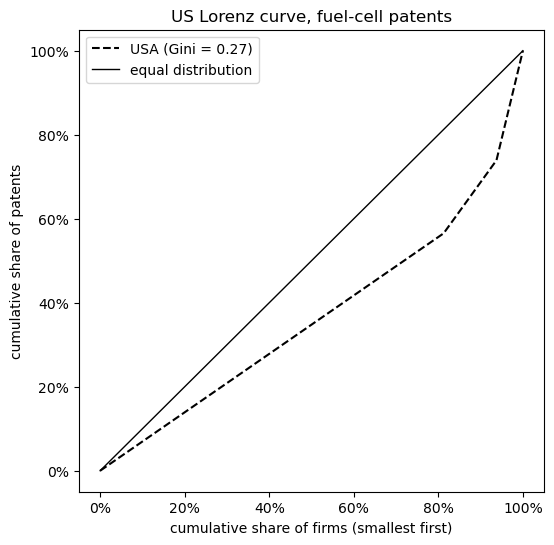

In [19]:
us_firms = firm_patents.loc[firm_patents["ctry"] == "US", "patents"].to_numpy()
share_of_firms, share_of_patents = lorenz_curve(us_firms)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(share_of_firms, share_of_patents, color="black", ls="--", label=f"USA (Gini = {gini(us_firms):.2f})")
ax.plot([0, 1], [0, 1], color="black", lw=1, label="equal distribution")
ax.set(title="US Lorenz curve, fuel-cell patents", xlabel="cumulative share of firms (smallest first)",
       ylabel="cumulative share of patents")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

This is the equivalent of the paper's **Figure 1**. Read a point of the curve as: "the smallest *x*% of the firms hold *y*% of the patents". The paper also checks Lotka's law by hand on the US firms: if $f(1)$ firms have one patent, the law predicts $f(1)/n^2$ firms with $n$ patents. The table below makes the same check.

In [20]:
# Lotka's law on the US firms: observed number of firms with n patents, and the number predicted by f(1) / n^2
observed = pd.Series(us_firms).value_counts().sort_index()
lotka_check = pd.DataFrame({
    "firms observed": observed,
    "firms predicted (f(1) / n²)": observed.get(1, 0) / observed.index.to_numpy() ** 2,
})
lotka_check.index.name = "patents per firm (n)"
lotka_check.head(10).round(1)

,firms observed,firms predicted (f(1) / n²)
patents per firm (n),,
1,13,13.0
2,2,3.2
6,1,0.4


### 4.7 Ranking the countries

Under each measure, we sort the countries from the **most** to the **least** concentrated. For CV, CR4, CR8, HH and Gini, a higher value means more concentrated. For Lotka, the more concentrated country is the one with $L$ **closer to 0**, so we sort on $\lvert L \rvert$ from the smallest.

In [21]:
MEASURES = ["CV", "CR4 (%)", "CR8 (%)", "HH", "Lotka L", "Gini"]

# a "concentration score" for each measure: higher = more concentrated
scores = table2.drop(index="Average")[MEASURES].copy()
scores["Lotka L"] = -scores["Lotka L"].abs()          # L close to 0 -> high score

# rank 1 = the most concentrated country under that measure
ranks = scores.rank(ascending=False)

table3 = pd.DataFrame({m: ranks[m].sort_values().index for m in MEASURES})
table3.index = range(1, len(table3) + 1)
table3.index.name = "rank"
table3

,CV,CR4 (%),CR8 (%),HH,Lotka L,Gini
rank,,,,,,
1,USA,Japan,Japan,Japan,USA,USA
2,Japan,USA,USA,USA,Japan,Japan



### 4.8 Do the measures agree? Kendall's tau-b

**Kendall's tau** compares two rankings by looking at every pair of countries: a pair is *concordant* if both measures put the two countries in the same order, *discordant* otherwise. Tau is (concordant − discordant) / number of pairs: +1 for identical rankings, −1 for opposite rankings, 0 for no relation. The **tau-b** version corrects for ties (two countries with the same value), and it is the default of `scipy.stats.kendalltau`.

In [22]:
table4 = pd.DataFrame(index=MEASURES, columns=MEASURES, dtype=object)
for a in MEASURES:
    for b in MEASURES:
        tau, p_value = stats.kendalltau(scores[a], scores[b], nan_policy="omit")   # tau-b
        star = "**" if p_value < 0.05 else "*" if p_value < 0.10 else ""        # ** 5%, * 10% significance
        table4.loc[a, b] = f"{tau:.3f}{star}"
table4

/tmp/ipykernel_438/1831916185.py:4: SmallSampleWarning: After omitting NaNs, one or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  tau, p_value = stats.kendalltau(scores[a], scores[b], nan_policy="omit")   # tau-b


,CV,CR4 (%),CR8 (%),HH,Lotka L,Gini
CV,nan,nan,nan,nan,nan,nan
CR4 (%),nan,1.000,1.000,1.000,nan,-1.000
CR8 (%),nan,1.000,1.000,1.000,nan,-1.000
HH,nan,1.000,1.000,1.000,nan,-1.000
Lotka L,nan,nan,nan,nan,nan,nan
Gini,nan,-1.000,-1.000,-1.000,nan,1.000


### 4.9 Two dimensions of concentration

The paper groups the measures in two families and places each country on two axes, using its **average rank**:

- x axis: average rank on **CR4, CR8, HH and Lotka**: the further right, the larger the number of firms with a significant number of patents;
- y axis: average rank on **CV and Gini**: the higher, the more similar the firms are to each other (homogeneous).

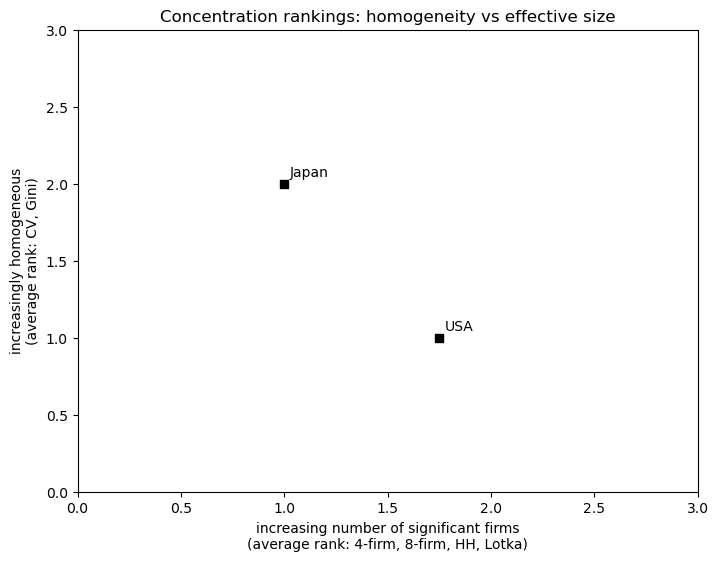

In [23]:
x = ranks[["CR4 (%)", "CR8 (%)", "HH", "Lotka L"]].mean(axis=1)
y = ranks[["CV", "Gini"]].mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, marker="s", color="black")
for country in ranks.index:
    ax.annotate(country, (x[country], y[country]), xytext=(4, 5), textcoords="offset points")
ax.set(xlim=(0, len(ranks) + 1), ylim=(0, len(ranks) + 1),
       title="Concentration rankings: homogeneity vs effective size",
       xlabel="increasing number of significant firms\n(average rank: 4-firm, 8-firm, HH, Lotka)",
       ylabel="increasingly homogeneous\n(average rank: CV, Gini)")
plt.show()

---

## 5. Answering the Step 2 questions for your sector

We now answer the four questions of Step 2 for a sector. The example is again **fuel cells**, but now as in the PW: **families** filed anywhere in the world, dated by their earliest priority year, from `YEAR_MIN` to `YEAR_MAX`. 

### 5.0 Data: the sector's families, their applicants and their CPC codes

In [24]:
# 1. sector families (CPC codes OR keywords), with their year = earliest priority year
by_cpc = (
    db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES))
)
sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (
        db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(SECTOR_KEYWORDS))
    )
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

# 2. the applicants of every family (one row per family and person)
q_sector = (
    db.query(families.c.unit_id, families.c.year, TLS206_PERSON.psn_id, TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
    .distinct()
)
raw_sector = patstat.df(q_sector)

# 3. the CPC codes of every family (for the subfields)
q_cpc = (
    db.query(families.c.unit_id, families.c.year,
             func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .distinct()
)
family_cpc = patstat.df(q_cpc)
print(f"{raw_sector['unit_id'].nunique():,} families")

672 families


In [25]:
# 4. the first patent ever (in any field) of each applicant, to identify newcomers to patenting
psn_ids = [int(i) for i in raw_sector["psn_id"].unique()]
first_patents = []
for start in range(0, len(psn_ids), 5000):                      # in chunks, to keep each query small
    q_first = (
        db.query(TLS206_PERSON.psn_id, func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
        .filter(TLS206_PERSON.psn_id.in_(psn_ids[start:start + 5000]),
                TLS207_PERS_APPLN.applt_seq_nr > 0,
                TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))   # drops the 9999 placeholders
        .group_by(TLS206_PERSON.psn_id)
    )
    first_patents.append(patstat.df(q_first))
first_patents = pd.concat(first_patents)

In [26]:
links = prepare_applicants(raw_sector)

# first patent ever of each consolidated applicant: the earliest among the PATSTAT names it groups
psn = raw_sector[["psn_id", "psn_name"]].drop_duplicates().merge(first_patents, on="psn_id")
psn["applicant"] = psn["psn_name"].map(consolidated_names(psn["psn_name"]))
first_ever = psn.groupby("applicant")["first_patent_year"].min()

print(f"{links['applicant'].nunique():,} applicants on {links['unit_id'].nunique():,} families")

806 applicants on 672 families


### 5.1 Question: how concentrated is the field, and is it consolidating?

First the six measures of Section 3 on the whole sector (all applicants, complete years), with **families** in place of patents.

In [27]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()

pd.Series(six_measures(families_per_applicant.to_numpy()), name=SECTOR_NAME).round(3).to_frame()

,Fuel cells
firms,799.000
patents (sum over firms),1074.000
CV,0.930
CR4 (%),5.121
CR8 (%),7.449
HH,0.002
1/HH,428.801
Lotka L,-2.189
Lotka p-value,0.000
Gini,0.229


A field is **consolidating** when **fewer applicants account for more of the inventions over time**. We compute HH, its numbers-equivalent (1/HH) and CR4 on windows of `WINDOW` consecutive years (one year alone is often too small): an increasing HH and CR4, and a decreasing 1/HH, mean consolidation.

### 5.2 Question: who are the incumbents, and who are the new entrants?

**Top applicants.** The deck table: the largest applicants with their type and country, their families, the year of their first family in the sector, and their status:

- **incumbent**: first family in the sector before `SPLIT_YEAR`;
- **entrant**: first family in the sector from `SPLIT_YEAR` on.

In [28]:
by_applicant = links.groupby("applicant")
top_applicants = pd.DataFrame({
    "type": by_applicant["type"].first(),
    "country": by_applicant["ctry"].first(),
    "families": by_applicant["unit_id"].nunique(),
    f"families since {SPLIT_YEAR}": links[links["year"] >= SPLIT_YEAR].groupby("applicant")["unit_id"].nunique(),
    "first year in the sector": by_applicant["year"].min(),
    "last year in the sector": by_applicant["year"].max(),
    "first patent ever": first_ever,
}).dropna(subset=["families"]).fillna({f"families since {SPLIT_YEAR}": 0})
top_applicants["status"] = np.where(top_applicants["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")
top_applicants = top_applicants.sort_values("families", ascending=False)
top_applicants.head(TOP_N)

,type,country,families,families since 2015,first year in the sector,last year in the sector,first patent ever,status
applicant,,,,,,,,
BLOOM ENERGY,firm,US,22,13.0,2005,2022,2005,incumbent
TOYOTA MOTOR,firm,JP,18,2.0,2000,2018,1974,incumbent
SUMITOMO ELECTRIC INDUSTRIES,unknown,JP,8,2.0,2001,2019,1964,incumbent
HUANENG CLEAN ENERGY RESEARCH INSTITUTE,firm,None,7,7.0,2016,2021,2015,entrant
CEA COMMISSARIAT A L ENERGIE ATOMIQUE,government / non-profit,FR,7,2.0,2009,2021,1962,incumbent
PANASONIC,firm,JP,7,0.0,2003,2011,1968,incumbent
FUELCELL ENERGY,firm,US,6,6.0,2016,2017,2004,entrant
LG FUEL CELL SYSTEMS,firm,US,5,2.0,2010,2017,2010,incumbent
SGCC STATE GRID CORPORATION OF CHINA,firm,None,5,4.0,2012,2022,2005,incumbent


**Entry and exit, year by year.** For each year $t$:

- **active applicants**: applicants with at least one family in $t$;
- **new to the sector**: active applicants whose first family in the sector is in $t$;
- **new to patenting**: active applicants whose first patent ever, in any field, is in $t$ ("they never patented before");
- **entrants' share of families**: share of the families of $t$ with at least one applicant new to the sector;
- **rate of disappearance**: share of the applicants active in $t$ that never file again in the sector. It is shown only up to 3 years before the last complete year: an applicant silent in the last years may simply not be published yet.

In the first years of the window almost every applicant looks "new", because we do not see its families before `YEAR_MIN`: read entry from a few years after `YEAR_MIN`.

In [29]:
first_year = by_applicant["year"].min()      # first family of each applicant in the sector
last_year = by_applicant["year"].max()       # last family of each applicant in the sector

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["new to patenting"] = active["year"] == active["applicant"].map(first_ever)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    new_to_patenting=("new to patenting", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

# share of each year's families with at least one applicant new to the sector
links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
entry_exit.round(1)

,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,,
2000,30,30,18,25,83.3,100.0
2001,13,9,5,8,61.5,66.7
2002,31,29,22,24,77.4,94.1
2003,48,46,32,41,85.4,92.0
2004,39,34,22,27,69.2,77.8
2005,34,27,24,26,76.5,65.0
2006,35,33,31,33,94.3,100.0
2007,48,43,33,39,81.2,80.0
2008,65,58,46,56,86.2,95.8


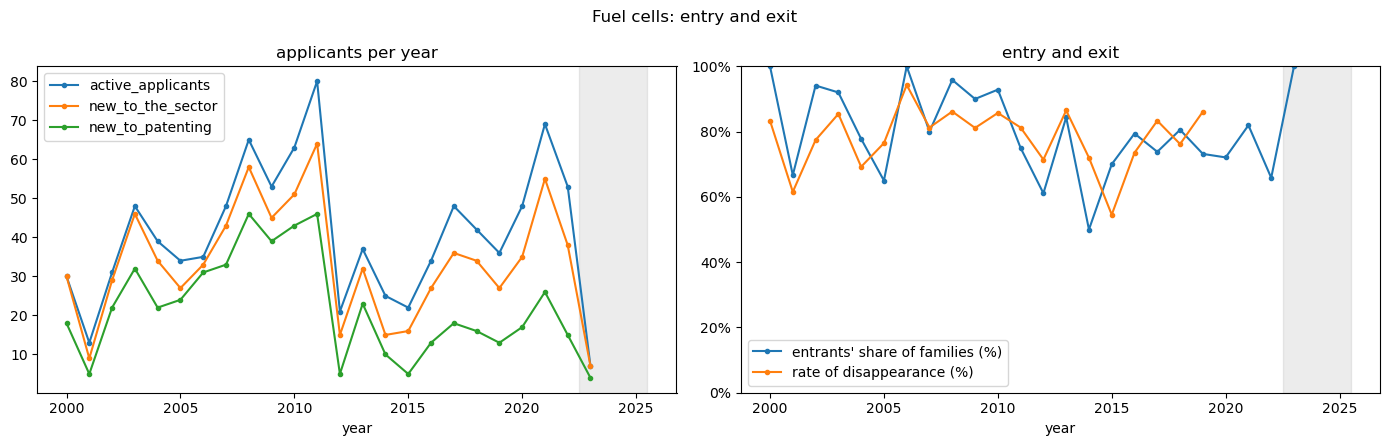

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
entry_exit[["active_applicants", "new_to_the_sector", "new_to_patenting"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="applicants per year", xlabel="year")
entry_exit[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="entry and exit", xlabel="year", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)   # incomplete years
fig.suptitle(f"{SECTOR_NAME}: entry and exit")
plt.tight_layout()
plt.show()

In [31]:
top = top_applicants.head(TOP_N)
incumbents = top[top["status"] == "incumbent"].index.tolist()
entrants = top[top["status"] == "entrant"].index.tolist()
recent_entry = entry_exit.loc[LAST_COMPLETE_YEAR - 4:LAST_COMPLETE_YEAR, "entrants' share of families (%)"].mean()

answer_box(
    "Who are the incumbents, and who are the new entrants?",
    f"Among the {TOP_N} largest applicants, <b>{len(incumbents)} are incumbents</b> and <b>{len(entrants)} are entrants</b>.",
    f"Largest incumbents: {', '.join(incumbents[:3]) or 'none'}. "
    f"Largest entrants (first family from {SPLIT_YEAR}): {', '.join(entrants[:3]) or 'none'}. "
    f"In the last five complete years, on average {recent_entry:.0f}% of each year's families had at least one applicant new to the sector.",
)

NameError: name 'answer_box' is not defined

### 5.3 Question: which subfields are growing fastest?

A **subfield** is a CPC group inside the sector. For fuel cells, the groups of H01M 8 separate the technologies (for example H01M 8/10: solid polymer electrolytes, PEM; H01M 8/12: high-temperature solid oxide cells, SOFC; H01M 8/24: stacks): check their titles in the CPC scheme. We count the families of each subfield in two periods of 5 years and compare them.

In [31]:
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)          # the last 5 complete years
PAST = (RECENT[0] - 5, RECENT[0] - 1)                          # the 5 years before


def subfield(cpc):
    "CPC group with the first two digits after the slash: H01M8/1004 -> H01M8/10."
    main_group, subgroup = cpc.split("/")
    return f"{main_group}/{subgroup[:2]}"


in_sector = family_cpc[family_cpc["cpc"].str.startswith(tuple(SECTOR_CPC_PREFIXES))].copy()
in_sector["subfield"] = in_sector["cpc"].map(subfield)
in_sector = in_sector.drop_duplicates(["unit_id", "subfield"])

past = in_sector[in_sector["year"].between(*PAST)].groupby("subfield")["unit_id"].nunique()
recent = in_sector[in_sector["year"].between(*RECENT)].groupby("subfield")["unit_id"].nunique()
subfields = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
subfields["growth (%)"] = (subfields.iloc[:, 1] / subfields.iloc[:, 0] - 1) * 100
subfields = subfields.sort_values(subfields.columns[1], ascending=False)
subfields.round(1)

,families 2013-2017,families 2018-2022,growth (%)
subfield,,,
Y02E60/50,140.0,187,33.6
H01M8/04,69.0,124,79.7
H01M8/06,46.0,95,106.5
H01M8/22,5.0,19,280.0
H01M8/18,26.0,17,-34.6
H01M8/24,12.0,15,25.0
H01M8/12,4.0,8,100.0
H01M8/10,10.0,7,-30.0
H01M8/00,3.0,6,100.0


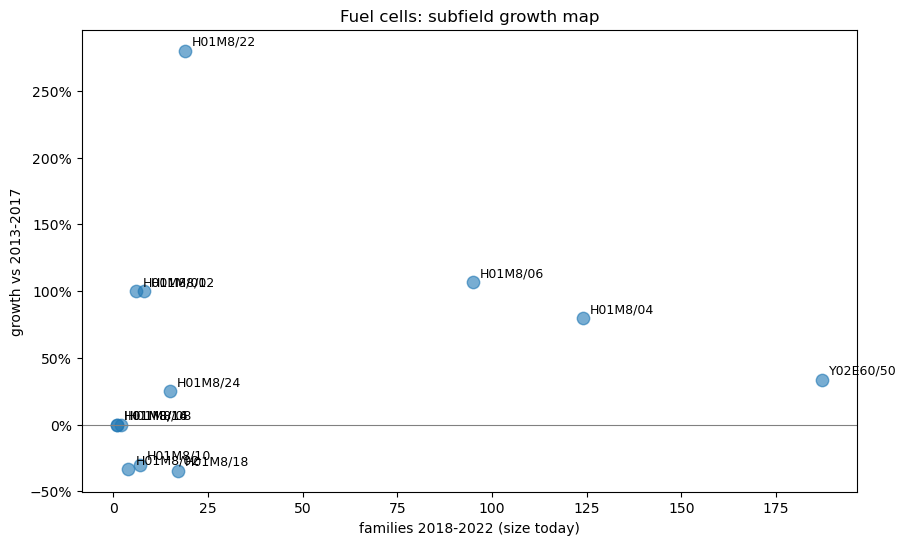

In [32]:
plot = subfields[subfields.iloc[:, 0] > 0]                   # growth is defined only if the subfield existed before
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot.iloc[:, 1], plot["growth (%)"], s=80, alpha=0.6)
for name, row in plot.iterrows():
    ax.annotate(name, (row.iloc[1], row["growth (%)"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title=f"{SECTOR_NAME}: subfield growth map", xlabel=f"families {RECENT[0]}-{RECENT[1]} (size today)",
       ylabel=f"growth vs {PAST[0]}-{PAST[1]}")
ax.yaxis.set_major_formatter(PercentFormatter(100))
plt.show()

In [ ]:
# fastest-growing subfields, among those at least as large as the median subfield today
size_today = plot.iloc[:, 1]
fastest = plot[size_today >= size_today.median()].sort_values("growth (%)", ascending=False).head(3)

answer_box(
    "Which subfields are growing fastest?",
    "<b>" + ", ".join(f"{name} ({row['growth (%)']:+.0f}%)" for name, row in fastest.iterrows()) + "</b>",
    f"Growth of families from {PAST[0]}-{PAST[1]} to {RECENT[0]}-{RECENT[1]}, among the subfields at least as large as the median one. "
    "Check the titles of these CPC groups in the CPC scheme.",
)

Top right: large and growing subfields; top left: small but growing fast; bottom: declining subfields. Topics extracted from abstracts are another way to define subfields: they are the subject of Landscaping tutorial 2 (patent text).

### 5.4 Question: which forces shape the field? PEST analysis

Patent data tell you **who** invents, **what** and **where**; they do not tell you **why**. To answer the last question of Step 2 we look outside PATSTAT.

**PEST** is an acronym for four sources of change: **political, economic, social and technological**. PEST analysis is a powerful and widely used tool for understanding strategic risk. It identifies the changes and the effects of the external macro environment on a firm's competitive position.

Strategists seek to understand external factors and evaluate how business models will have to evolve to adapt to their environment. The impacts of external factors are mitigated through preemptive strategy, and new opportunities are exploited in the wake of new competitive positions that may be created in the process.

PEST analysis is used in conjunction with **SWOT** (internal strengths and weaknesses, external opportunities and threats) and **Porter's five forces** model (encompassing the external effect of suppliers, consumer demand, new entrants, substitute products and competitive rivalry). It works best when the environmental factors are analysed from the perspective of the firm's resources, capabilities and core competences.

Exploring a firm's external macro environment involves five main stages:

1. identifying the PEST factors;
2. analysing their possible effects on the firm;
3. categorising them into opportunities and threats;
4. prioritising the factors;
5. developing corrective or preemptive strategic action.

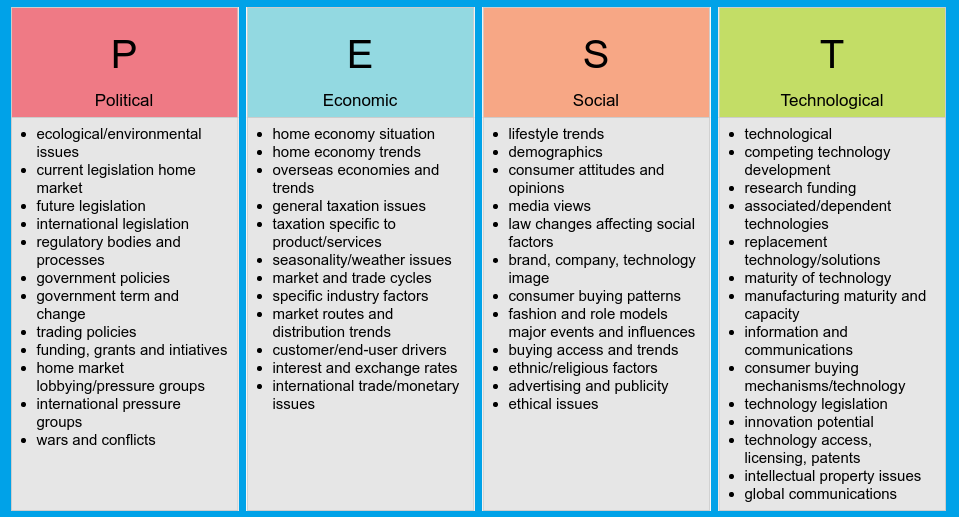

#### Example of a PEST analysis: PepsiCo

PepsiCo, the largest beverage company in the world, accounts for about 40 percent of the beverage market globally. It operates in 150 countries, including India. Using a PEST analysis, let us see what changes in PepsiCo's external environment (PEST factors) in these countries might affect the expectations of its global results.

**Political factors**

- Governments may change their tax policies and tax rates, which would affect profits.
- Governments could bring in stricter capital transfer laws and labour laws, which would affect its resource and employee management, respectively.
- Civil unrest and political instability exist in some countries, which may unsettle its expansion plans.

**Economic factors**

- Although the economies of many countries are showing signs of recovery, the threats of recession continue, which would affect consumer spending.
- Rapid fluctuations in currency rates have influenced the prices of raw materials, which would force the company to review its sourcing plans.

**Social factors**

- Consumer awareness about the impact of carbonated drinks is increasing, which would affect sales.
- Healthy lifestyles are gaining popularity, which, again, would affect sales.

**Technological factors**

- Technological innovations have been made in beverage manufacturing, which would help maintain product quality.
- Internet-enabled technology has benefited manufacturing, which would facilitate smooth processes.

---

← [10 · Patent attributes](10_patent_attributes.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)